# BirdCLEF 2025 — Exploratory Data Analysis

Understand the dataset before fine-tuning pretrained audio models.

**Data location**: `~/ps-clef2026_birdclef-0/data/birdclef-2025/`

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

DATA_DIR = Path(os.path.expanduser("~/ps-clef2026_birdclef-0/data/birdclef-2025"))
print(f"Data directory: {DATA_DIR}")
print(f"Exists: {DATA_DIR.exists()}")
if DATA_DIR.exists():
    print(f"Contents: {list(DATA_DIR.iterdir())}")

Data directory: /storage/home/hcoda1/9/mgustineli3/ps-clef2026_birdclef-0/data/birdclef-2025
Exists: True
Contents: [PosixPath('/storage/home/hcoda1/9/mgustineli3/ps-clef2026_birdclef-0/data/birdclef-2025/recording_location.txt'), PosixPath('/storage/home/hcoda1/9/mgustineli3/ps-clef2026_birdclef-0/data/birdclef-2025/sample_submission.csv'), PosixPath('/storage/home/hcoda1/9/mgustineli3/ps-clef2026_birdclef-0/data/birdclef-2025/taxonomy.csv'), PosixPath('/storage/home/hcoda1/9/mgustineli3/ps-clef2026_birdclef-0/data/birdclef-2025/test_soundscapes'), PosixPath('/storage/home/hcoda1/9/mgustineli3/ps-clef2026_birdclef-0/data/birdclef-2025/train.csv'), PosixPath('/storage/home/hcoda1/9/mgustineli3/ps-clef2026_birdclef-0/data/birdclef-2025/train_audio'), PosixPath('/storage/home/hcoda1/9/mgustineli3/ps-clef2026_birdclef-0/data/birdclef-2025/train_soundscapes')]


## 1. Metadata Overview

In [2]:
# Load training metadata
meta = pd.read_csv(DATA_DIR / "train.csv")
print(f"Shape: {meta.shape}")
print(f"\nColumns: {list(meta.columns)}")
meta.head()

Shape: (28564, 13)

Columns: ['primary_label', 'secondary_labels', 'type', 'filename', 'collection', 'rating', 'url', 'latitude', 'longitude', 'scientific_name', 'common_name', 'author', 'license']


,primary_label,secondary_labels,type,filename,collection,rating,url,latitude,longitude,scientific_name,common_name,author,license
0,1139490,[''],[''],1139490/CSA36385.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos...,7.3206,-73.7128,Ragoniella pulchella,Ragoniella pulchella,Fabio A. Sarria-S,cc-by-nc-sa 4.0
1,1139490,[''],[''],1139490/CSA36389.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos...,7.3206,-73.7128,Ragoniella pulchella,Ragoniella pulchella,Fabio A. Sarria-S,cc-by-nc-sa 4.0
2,1192948,[''],[''],1192948/CSA36358.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos...,7.3791,-73.7313,Oxyprora surinamensis,Oxyprora surinamensis,Fabio A. Sarria-S,cc-by-nc-sa 4.0
3,1192948,[''],[''],1192948/CSA36366.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos...,7.2800,-73.8582,Oxyprora surinamensis,Oxyprora surinamensis,Fabio A. Sarria-S,cc-by-nc-sa 4.0
4,1192948,[''],[''],1192948/CSA36373.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos...,7.3791,-73.7313,Oxyprora surinamensis,Oxyprora surinamensis,Fabio A. Sarria-S,cc-by-nc-sa 4.0


In [3]:
meta.describe(include="all")

,primary_label,secondary_labels,type,filename,collection,rating,url,latitude,longitude,scientific_name,common_name,author,license
count,28564,28564,28564,28564,28564,28564.000000,28564,27755.000000,27755.000000,28564,28564,28564,28564
unique,206,745,736,28564,3,NaN,28552,NaN,NaN,206,206,2493,8
top,grekis,[''],['song'],1139490/CSA36385.ogg,XC,NaN,https://static.inaturalist.org/sounds/1020465.wav,NaN,NaN,Pitangus sulphuratus,Great Kiskadee,JAYRSON ARAUJO DE OLIVEIRA,cc-by-nc-sa 4.0
freq,990,25885,9437,1,21204,NaN,4,NaN,NaN,990,990,1780,16813
mean,NaN,NaN,NaN,NaN,NaN,2.917063,NaN,-0.533480,-68.524380,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,1.964896,NaN,17.609276,21.614566,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,-54.857400,-163.680000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,-15.084600,-79.649200,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,4.000000,NaN,1.131600,-73.495400,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,4.500000,NaN,9.511000,-53.801800,NaN,NaN,NaN,NaN


In [4]:
meta.info()

<class 'pandas.DataFrame'>
RangeIndex: 28564 entries, 0 to 28563
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   primary_label     28564 non-null  str    
 1   secondary_labels  28564 non-null  str    
 2   type              28564 non-null  str    
 3   filename          28564 non-null  str    
 4   collection        28564 non-null  str    
 5   rating            28564 non-null  float64
 6   url               28564 non-null  str    
 7   latitude          27755 non-null  float64
 8   longitude         27755 non-null  float64
 9   scientific_name   28564 non-null  str    
 10  common_name       28564 non-null  str    
 11  author            28564 non-null  str    
 12  license           28564 non-null  str    
dtypes: float64(3), str(10)
memory usage: 6.8 MB


## 2. Species Distribution

In [5]:
# Species counts
species_col = "primary_label" if "primary_label" in meta.columns else "species"
species_counts = meta[species_col].value_counts()

print(f"Number of species: {len(species_counts)}")
print("\nTop 20 species:")
print(species_counts.head(20))
print("\nBottom 20 species:")
print(species_counts.tail(20))
print(
    f"\nRecordings per species — min: {species_counts.min()}, "
    f"median: {species_counts.median():.0f}, "
    f"max: {species_counts.max()}"
)

Number of species: 206

Top 20 species:
primary_label
grekis     990
compau     808
trokin     787
roahaw     709
banana     610
whtdov     572
socfly1    543
yeofly1    525
bobfly1    514
wbwwre1    499
soulap1    487
sobtyr1    478
trsowl     470
laufal1    467
strcuc1    431
bbwduc     424
saffin     419
amekes     409
tropar     397
compot1    383
Name: count, dtype: int64

Bottom 20 species:
primary_label
868458     4
1194042    3
1462711    3
24292      3
65419      3
1139490    2
21038      2
21116      2
41778      2
42087      2
42113      2
47067      2
476537     2
528041     2
64862      2
66016      2
66531      2
66578      2
67082      2
81930      2
Name: count, dtype: int64

Recordings per species — min: 2, median: 80, max: 990


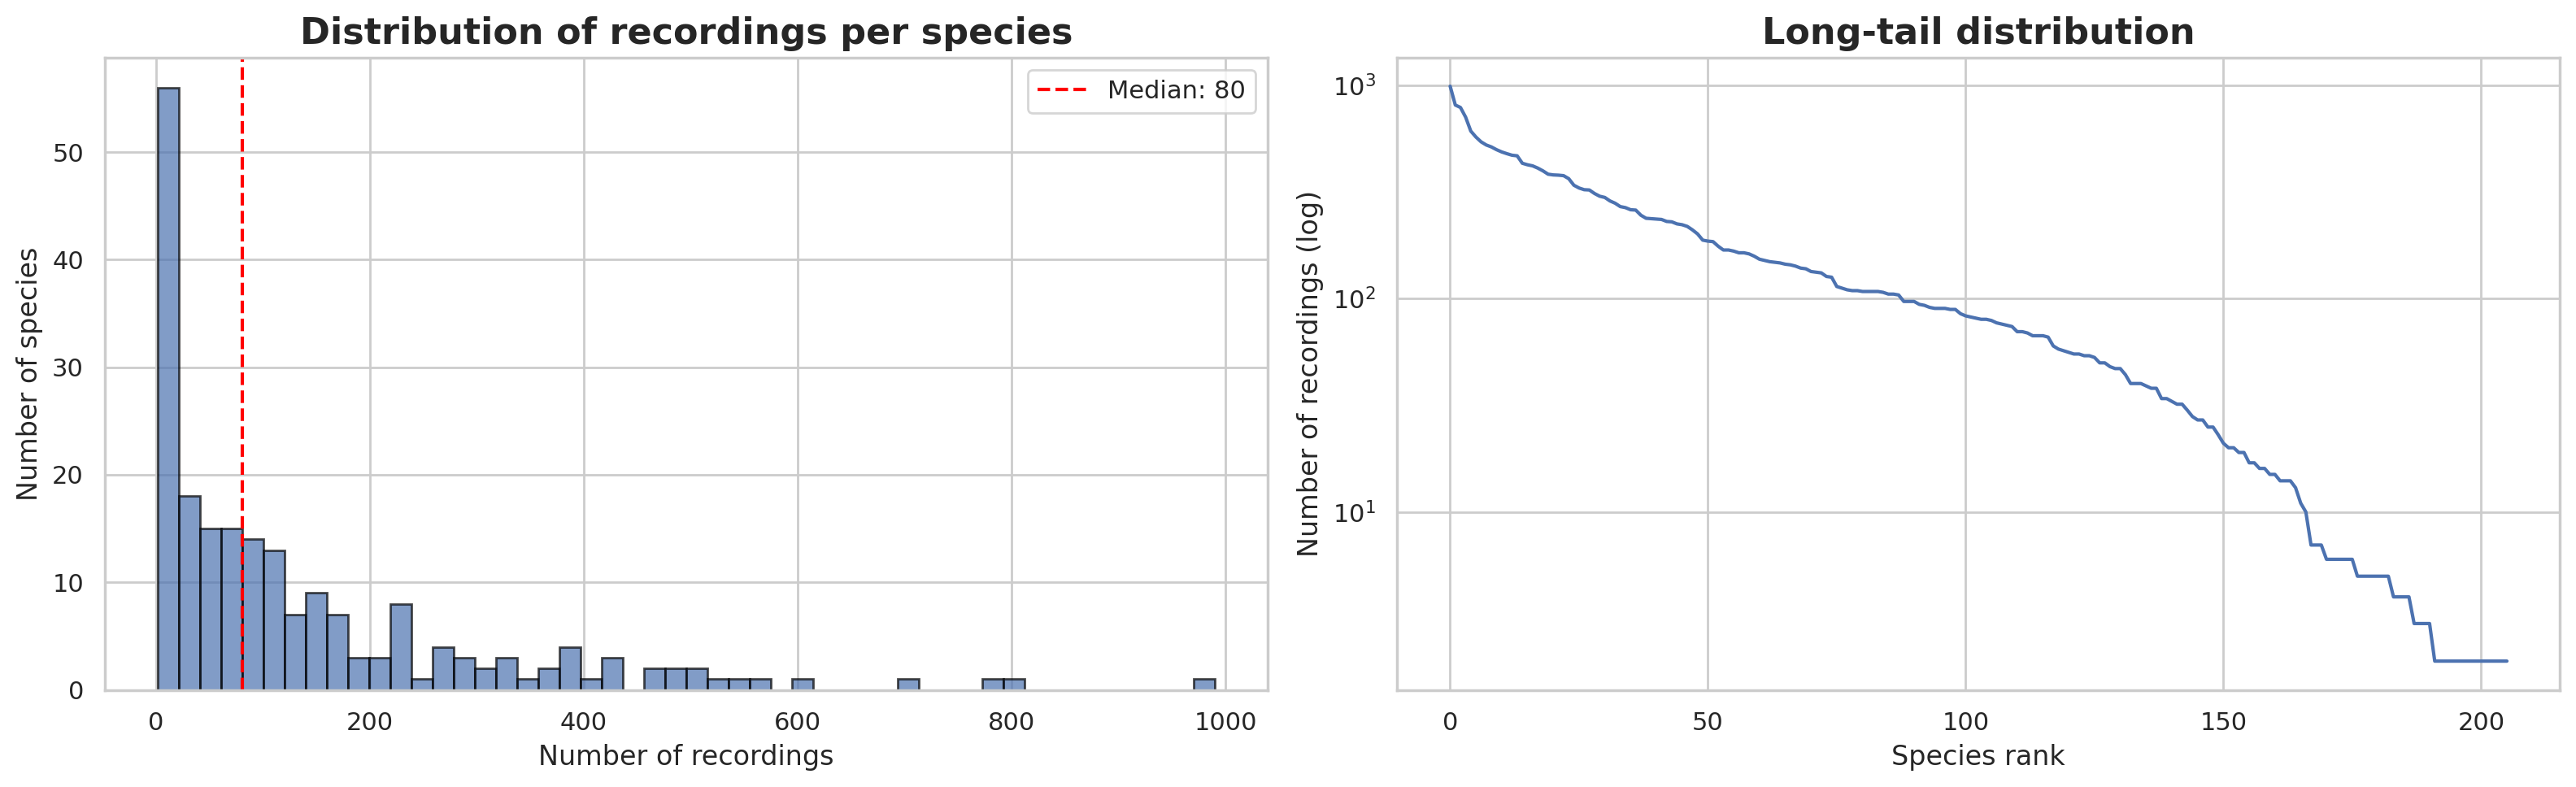

In [12]:
# Species distribution plot
fig, axes = plt.subplots(1, 2, figsize=(16, 5), dpi=200)

# Histogram of recordings per species
axes[0].hist(species_counts.values, bins=50, edgecolor="black", alpha=0.7)
axes[0].set_xlabel("Number of recordings")
axes[0].set_ylabel("Number of species")
axes[0].set_title("Distribution of recordings per species", weight="bold", fontsize=16)
axes[0].axvline(
    species_counts.median(),
    color="red",
    linestyle="--",
    label=f"Median: {species_counts.median():.0f}",
)
axes[0].legend()

# Sorted species counts (log scale)
axes[1].plot(range(len(species_counts)), species_counts.values)
axes[1].set_xlabel("Species rank")
axes[1].set_ylabel("Number of recordings (log)")
axes[1].set_title("Long-tail distribution", weight="bold", fontsize=16)
axes[1].set_yscale("log")

plt.tight_layout()
plt.show()

## 3. Audio Properties

In [13]:
import librosa
import numpy as np

# Sample a few audio files to check properties
train_audio_dir = DATA_DIR / "train_audio"
if train_audio_dir.exists():
    species_dirs = sorted([d for d in train_audio_dir.iterdir() if d.is_dir()])
    print(f"Species directories: {len(species_dirs)}")

    # Sample 100 files across species
    sample_files = []
    for sp_dir in species_dirs[:50]:
        ogg_files = list(sp_dir.glob("*.ogg"))
        if ogg_files:
            sample_files.extend(ogg_files[:2])

    durations = []
    sample_rates = []
    for f in sample_files:
        try:
            info = librosa.get_duration(path=f)
            durations.append(info)
            y, sr = librosa.load(f, sr=None, duration=0.1)
            sample_rates.append(sr)
        except Exception as e:
            print(f"Error reading {f.name}: {e}")

    print(f"\nSampled {len(durations)} files")
    print(f"Sample rates: {set(sample_rates)}")
    print(
        f"Duration — min: {min(durations):.1f}s, median: {np.median(durations):.1f}s, "
        f"max: {max(durations):.1f}s, mean: {np.mean(durations):.1f}s"
    )

Species directories: 206

Sampled 100 files
Sample rates: {32000}
Duration — min: 1.2s, median: 30.0s, max: 382.3s, mean: 58.9s


## 4. Geographic Coverage

Recordings with coordinates: 27755 / 28564 (97.2%)


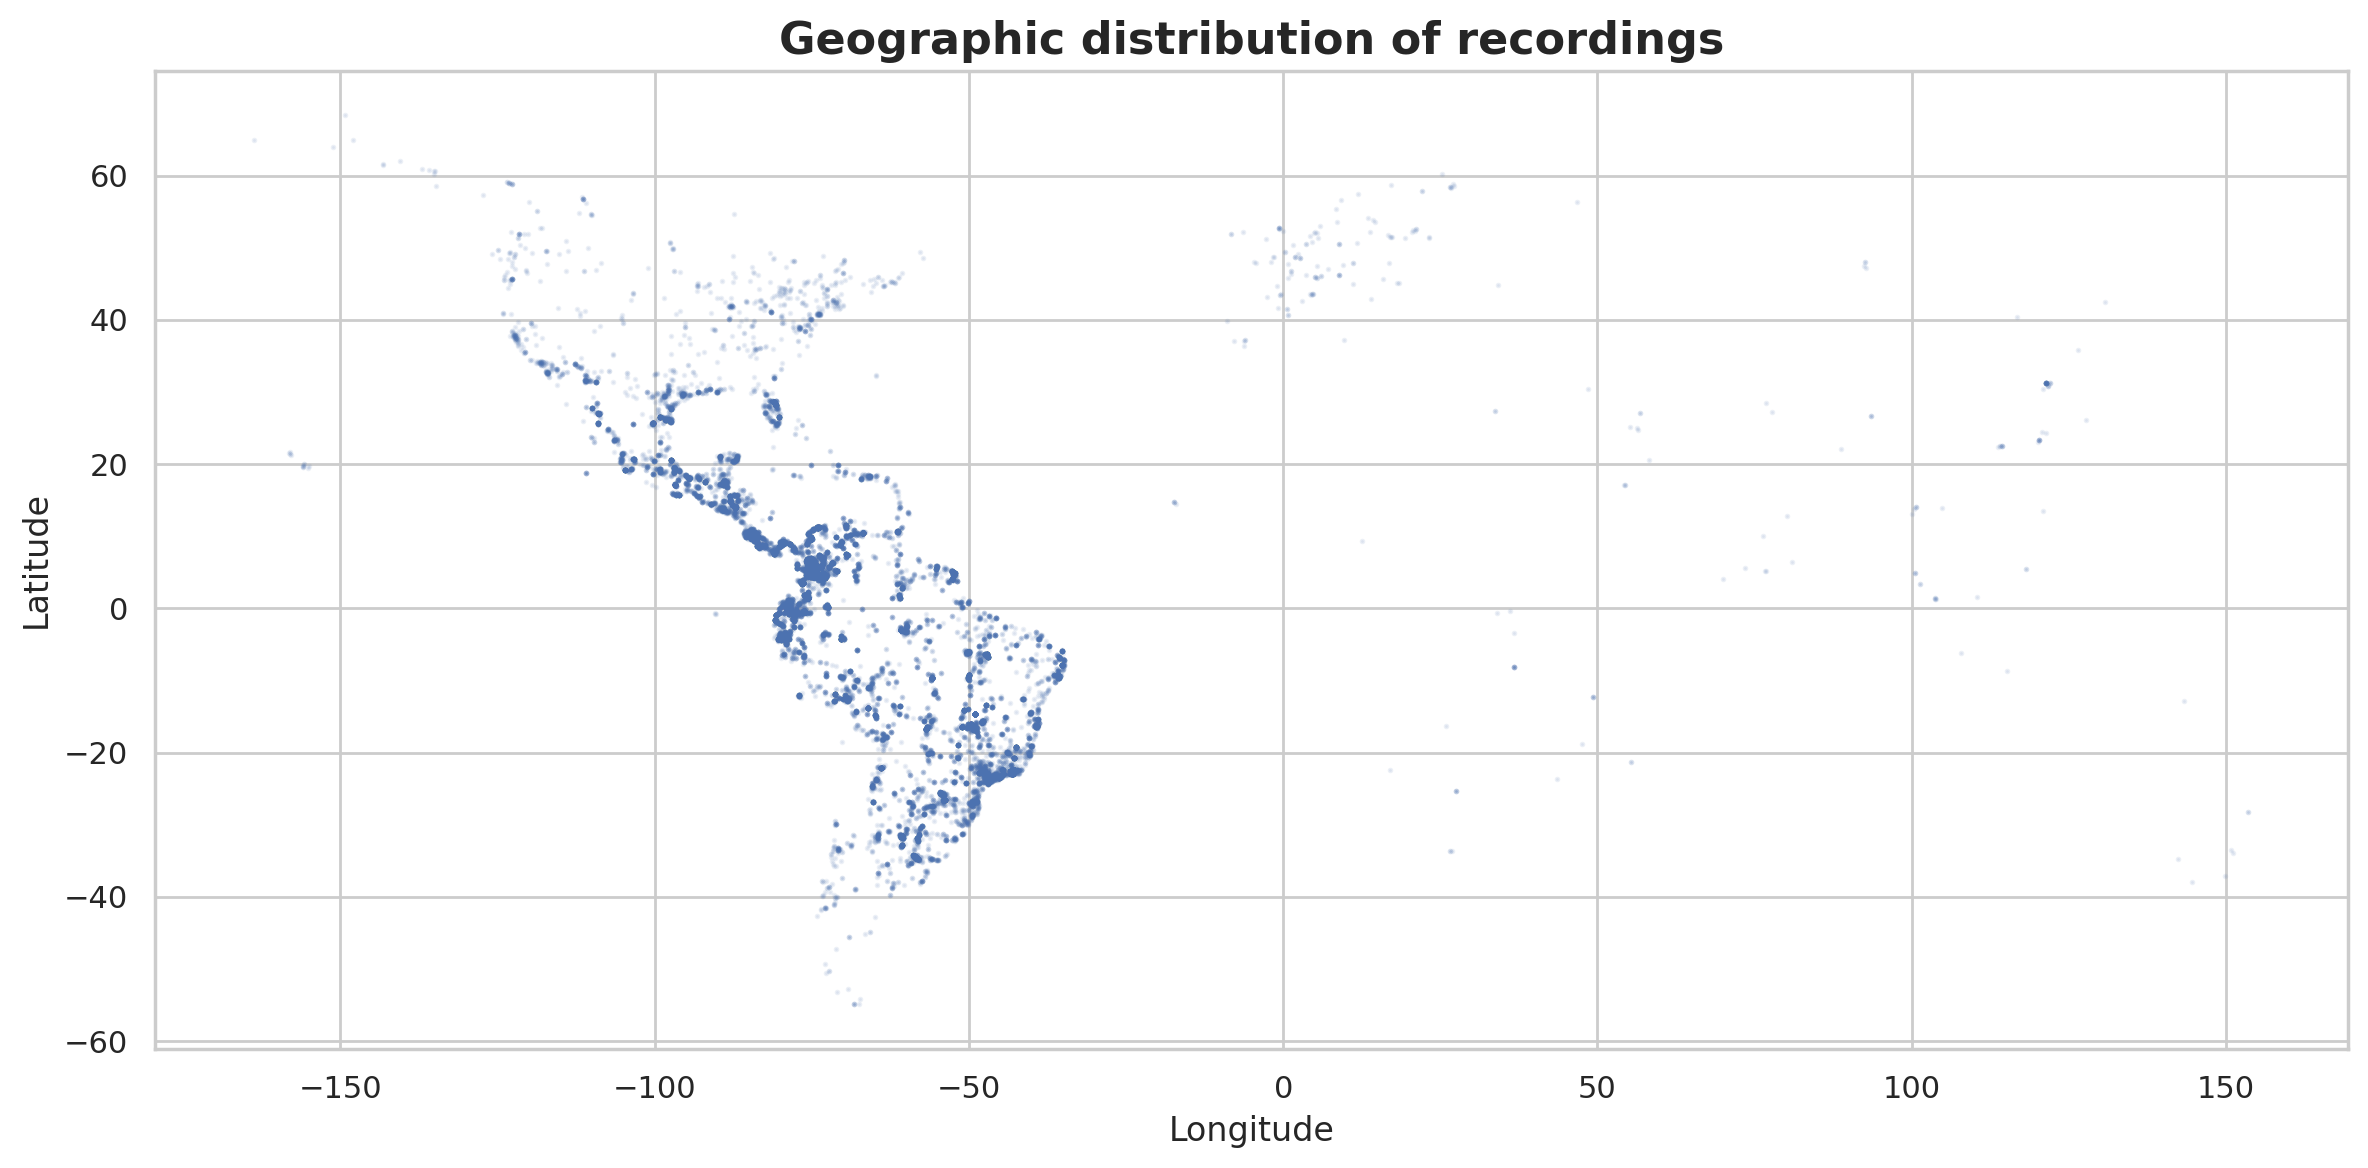

In [ ]:
lat_col = "latitude" if "latitude" in meta.columns else None
lon_col = "longitude" if "longitude" in meta.columns else None

if lat_col and lon_col:
    valid_coords = meta.dropna(subset=[lat_col, lon_col])
    print(
        f"Recordings with coordinates: {len(valid_coords)} / {len(meta)} ({len(valid_coords) / len(meta) * 100:.1f}%)"
    )

    fig, ax = plt.subplots(figsize=(12, 6), dpi=200)
    ax.scatter(valid_coords[lon_col], valid_coords[lat_col], alpha=0.1, s=1)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title("Geographic distribution of recordings", weight="bold", fontsize=16)
    plt.tight_layout()
    plt.show()
else:
    print("No latitude/longitude columns found in metadata.")

## 5. Taxonomy

In [18]:
taxonomy_file = DATA_DIR / "taxonomy.csv"
if taxonomy_file.exists():
    taxonomy = pd.read_csv(taxonomy_file)
    print(f"Taxonomy shape: {taxonomy.shape}")
    print(f"Columns: {list(taxonomy.columns)}")
    taxonomy.head(10)
else:
    print("No taxonomy.csv found.")

Taxonomy shape: (206, 5)
Columns: ['primary_label', 'inat_taxon_id', 'scientific_name', 'common_name', 'class_name']


## 6. Summary

Key findings to inform model fine-tuning:

- **Number of species**: 206 (labeled by numeric IDs and species codes)
- **Total recordings**: 28,564 across 3 collections (XC: 21,204, CSA, iNaturalist)
- **Class imbalance**: Severe long-tail — max 990 (`grekis`), median 80, min 2 recordings per species. Many rare species have <10 samples.
- **Audio format**: `.ogg`, 32kHz sample rate (uniform). Pretrained models (BEATs/EAT) expect 16kHz — resampling required.
- **Duration range**: 1.2s–382.3s (median 30.0s, mean 58.9s). 5s chunking will yield ~6 chunks per median recording.
- **Geographic coverage**: 97.2% of recordings have coordinates. Heavily concentrated in South America (median lat ~1.1°, median lon ~-73.5°).
- **Quality ratings**: Median 4.0 (scale 0–5), but many recordings rated 0.0 (unrated).

### Implications for training

1. **Class imbalance** → Use weighted loss or oversampling for rare species (bottom ~50 species have <20 recordings each)
2. **Resampling** → Resample 32kHz → 16kHz before feeding to BEATs/EAT encoder
3. **Chunking** → 5s non-overlapping chunks will produce ~6x more training samples than one-clip-per-recording
4. **Quality filtering** → Consider filtering or downweighting recordings with rating 0.0
5. **Domain gap** → Training data is focal recordings; evaluation is on soundscapes (different acoustic conditions)